## Setup and Reproducibility


In [2]:
# Import the libraries, set the random seed, and select the training device.
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from google.colab import drive
drive.mount('/content/drive')


from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Mounted at /content/drive
Device: cuda


## CIFAR 10 Dataset and Normalization


In [3]:
# Normalize CIFAR-10 and download the training and testing datasets.
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

full_train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

class_names = full_train_dataset.classes

print("Classes:", class_names)
print("Full training observations:", len(full_train_dataset))
print("Testing observations:", len(test_dataset))

100%|██████████| 170M/170M [26:49<00:00, 106kB/s] 


Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Full training observations: 50000
Testing observations: 10000


## Training Validation and Test Split


In [4]:
# Split the original training data into training and validation sets.
train_size = 45000
validation_size = len(full_train_dataset) - train_size

split_generator = torch.Generator().manual_seed(seed)

train_dataset, validation_dataset = random_split(
    full_train_dataset,
    [train_size, validation_size],
    generator=split_generator
)

print("Training observations:", len(train_dataset))
print("Validation observations:", len(validation_dataset))
print("Testing observations:", len(test_dataset))

Training observations: 45000
Validation observations: 5000
Testing observations: 10000


## Data Loaders


In [5]:
# Create data loaders for training, validation, and testing.
batch_size = 128
pin_memory = device.type == "cuda"

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=pin_memory
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=pin_memory
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=pin_memory
)

## Input Shape Check


In [6]:
# Check the image and label shapes before building the network.
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("One image shape:", images[0].shape)
print("Flattened image size:", images[0].numel())

Image batch shape: torch.Size([128, 3, 32, 32])
Label batch shape: torch.Size([128])
One image shape: torch.Size([3, 32, 32])
Flattened image size: 3072


In [7]:
# Display the device used for training.
print("Training device:", device)

Training device: cuda


## Problem 1a Baseline FCNN


In [8]:
# Build the baseline FCNN with two hidden ReLU layers.
class BaselineFCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * 32 * 32, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.network(x)


baseline_model = BaselineFCNN().to(device)

print(baseline_model)

BaselineFCNN(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)


In [9]:
# Count the trainable parameters in the baseline model.
baseline_parameters = sum(
    parameter.numel()
    for parameter in baseline_model.parameters()
    if parameter.requires_grad
)

print(f"Baseline trainable parameters: {baseline_parameters:,}")

Baseline trainable parameters: 1,707,274


## Shared Training and Evaluation Functions


In [10]:
# Evaluate model loss and accuracy without updating the weights.
def evaluate_model(model, data_loader, criterion):
    model.eval()

    total_loss = 0
    correct_predictions = 0
    total_observations = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct_predictions += (predictions == labels).sum().item()
            total_observations += labels.size(0)

    average_loss = total_loss / total_observations
    accuracy = correct_predictions / total_observations

    return average_loss, accuracy

In [11]:
# Train a model with Adam, validation tracking, and early stopping.
def train_model(model, train_loader, validation_loader,
                learning_rate=0.001, max_epochs=100, patience=10):

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "validation_loss": [],
        "validation_accuracy": []
    }

    best_validation_loss = float("inf")
    best_model_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.time()

    for epoch in range(max_epochs):
        model.train()

        running_loss = 0
        correct_predictions = 0
        total_observations = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct_predictions += (predictions == labels).sum().item()
            total_observations += labels.size(0)

        train_loss = running_loss / total_observations
        train_accuracy = correct_predictions / total_observations

        validation_loss, validation_accuracy = evaluate_model(
            model, validation_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["validation_loss"].append(validation_loss)
        history["validation_accuracy"].append(validation_accuracy)

        print(
            f"Epoch {epoch + 1:3d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Loss: {validation_loss:.4f} | "
            f"Val Acc: {validation_accuracy:.4f}"
        )

        if validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            best_epoch = epoch + 1
            best_model_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"\nEarly stopping at epoch {epoch + 1}")
            break

    if device.type == "cuda":
        torch.cuda.synchronize()

    training_time = time.time() - start_time

    model.load_state_dict(best_model_state)

    print(f"\nBest epoch: {best_epoch}")
    print(f"Best validation loss: {best_validation_loss:.4f}")
    print(f"Training time: {training_time:.2f} seconds")

    return model, history, training_time, best_epoch

## Baseline Training and Results


In [13]:
# Train the baseline network and save its best validation weights.
baseline_model = BaselineFCNN().to(device)

baseline_model, baseline_history, baseline_training_time, baseline_best_epoch = train_model(
    baseline_model,
    train_loader,
    validation_loader,
    learning_rate=0.001,
    max_epochs=100,
    patience=10
)

Epoch   1 | Train Loss: 1.6595 | Train Acc: 0.4111 | Val Loss: 1.5165 | Val Acc: 0.4664
Epoch   2 | Train Loss: 1.4404 | Train Acc: 0.4903 | Val Loss: 1.4428 | Val Acc: 0.4958
Epoch   3 | Train Loss: 1.3351 | Train Acc: 0.5285 | Val Loss: 1.3989 | Val Acc: 0.5110
Epoch   4 | Train Loss: 1.2426 | Train Acc: 0.5618 | Val Loss: 1.4133 | Val Acc: 0.4918
Epoch   5 | Train Loss: 1.1595 | Train Acc: 0.5907 | Val Loss: 1.4233 | Val Acc: 0.5146
Epoch   6 | Train Loss: 1.0875 | Train Acc: 0.6118 | Val Loss: 1.4176 | Val Acc: 0.5162
Epoch   7 | Train Loss: 1.0074 | Train Acc: 0.6415 | Val Loss: 1.4366 | Val Acc: 0.5170
Epoch   8 | Train Loss: 0.9378 | Train Acc: 0.6679 | Val Loss: 1.4578 | Val Acc: 0.5218
Epoch   9 | Train Loss: 0.8667 | Train Acc: 0.6932 | Val Loss: 1.4985 | Val Acc: 0.5264
Epoch  10 | Train Loss: 0.7995 | Train Acc: 0.7142 | Val Loss: 1.5456 | Val Acc: 0.5304
Epoch  11 | Train Loss: 0.7304 | Train Acc: 0.7385 | Val Loss: 1.6092 | Val Acc: 0.5280
Epoch  12 | Train Loss: 0.6822 |

In [14]:
# Evaluate the best baseline model on all three data splits.
criterion = nn.CrossEntropyLoss()

baseline_train_loss, baseline_train_accuracy = evaluate_model(
    baseline_model, train_loader, criterion
)

baseline_validation_loss, baseline_validation_accuracy = evaluate_model(
    baseline_model, validation_loader, criterion
)

baseline_test_loss, baseline_test_accuracy = evaluate_model(
    baseline_model, test_loader, criterion
)

baseline_parameters = sum(
    parameter.numel()
    for parameter in baseline_model.parameters()
    if parameter.requires_grad
)

print("Baseline FCNN Final Results")
print(f"Best epoch:         {baseline_best_epoch}")
print(f"Training time:      {baseline_training_time:.2f} seconds")
print(f"Training loss:      {baseline_train_loss:.4f}")
print(f"Training accuracy:  {baseline_train_accuracy:.4f}")
print(f"Validation loss:    {baseline_validation_loss:.4f}")
print(f"Validation accuracy:{baseline_validation_accuracy:.4f}")
print(f"Evaluation loss:    {baseline_test_loss:.4f}")
print(f"Evaluation accuracy:{baseline_test_accuracy:.4f}")
print(f"Trainable parameters: {baseline_parameters:,}")

Baseline FCNN Final Results
Best epoch:         3
Training time:      148.49 seconds
Training loss:      1.2029
Training accuracy:  0.5740
Validation loss:    1.3989
Validation accuracy:0.5110
Evaluation loss:    1.3917
Evaluation accuracy:0.5106
Trainable parameters: 1,707,274


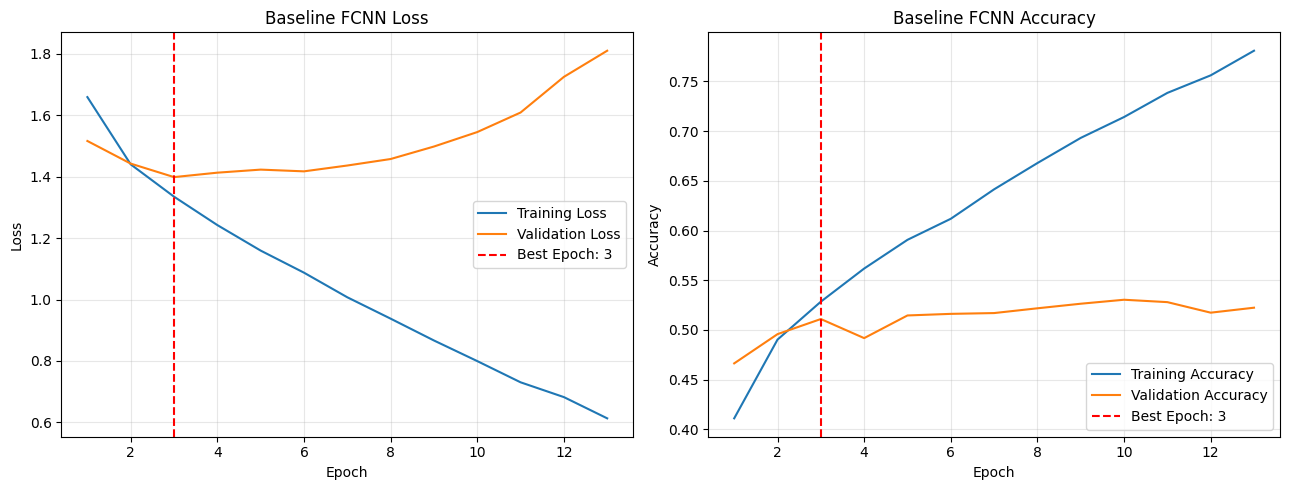

In [15]:
# Plot the baseline loss and accuracy curves.
epochs_ran = range(1, len(baseline_history["train_loss"]) + 1)

plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.plot(
    epochs_ran,
    baseline_history["train_loss"],
    label="Training Loss"
)
plt.plot(
    epochs_ran,
    baseline_history["validation_loss"],
    label="Validation Loss"
)
plt.axvline(
    baseline_best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch: {baseline_best_epoch}"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline FCNN Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(
    epochs_ran,
    baseline_history["train_accuracy"],
    label="Training Accuracy"
)
plt.plot(
    epochs_ran,
    baseline_history["validation_accuracy"],
    label="Validation Accuracy"
)
plt.axvline(
    baseline_best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch: {baseline_best_epoch}"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline FCNN Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Problem 1b Four Hidden Layer FCNN


In [16]:
# Build the deeper FCNN with four hidden ReLU layers.
class DeepFCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(3 * 32 * 32, 512),
            nn.ReLU(),

            nn.Linear(512, 256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


deep_model = DeepFCNN().to(device)

deep_parameters = sum(
    parameter.numel()
    for parameter in deep_model.parameters()
    if parameter.requires_grad
)

print(deep_model)
print(f"Deep FCNN trainable parameters: {deep_parameters:,}")

DeepFCNN(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=128, bias=True)
    (6): ReLU()
    (7): Linear(in_features=128, out_features=64, bias=True)
    (8): ReLU()
    (9): Linear(in_features=64, out_features=10, bias=True)
  )
)
Deep FCNN trainable parameters: 1,746,506


In [17]:
# Train the four-hidden-layer FCNN using the same settings.
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

deep_model = DeepFCNN().to(device)

deep_model, deep_history, deep_training_time, deep_best_epoch = train_model(
    model=deep_model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    learning_rate=0.001,
    max_epochs=100,
    patience=10
)

Epoch   1 | Train Loss: 1.6945 | Train Acc: 0.3950 | Val Loss: 1.5679 | Val Acc: 0.4500
Epoch   2 | Train Loss: 1.4701 | Train Acc: 0.4796 | Val Loss: 1.4426 | Val Acc: 0.4864
Epoch   3 | Train Loss: 1.3453 | Train Acc: 0.5258 | Val Loss: 1.3944 | Val Acc: 0.5136
Epoch   4 | Train Loss: 1.2537 | Train Acc: 0.5567 | Val Loss: 1.3915 | Val Acc: 0.5166
Epoch   5 | Train Loss: 1.1654 | Train Acc: 0.5873 | Val Loss: 1.3718 | Val Acc: 0.5316
Epoch   6 | Train Loss: 1.0887 | Train Acc: 0.6145 | Val Loss: 1.3784 | Val Acc: 0.5286
Epoch   7 | Train Loss: 1.0190 | Train Acc: 0.6375 | Val Loss: 1.4116 | Val Acc: 0.5292
Epoch   8 | Train Loss: 0.9388 | Train Acc: 0.6678 | Val Loss: 1.4088 | Val Acc: 0.5418
Epoch   9 | Train Loss: 0.8682 | Train Acc: 0.6879 | Val Loss: 1.4850 | Val Acc: 0.5292
Epoch  10 | Train Loss: 0.8018 | Train Acc: 0.7150 | Val Loss: 1.4824 | Val Acc: 0.5352
Epoch  11 | Train Loss: 0.7367 | Train Acc: 0.7365 | Val Loss: 1.5469 | Val Acc: 0.5348
Epoch  12 | Train Loss: 0.6876 |

In [18]:
# Evaluate the best four-hidden-layer model.
criterion = nn.CrossEntropyLoss()

deep_train_loss, deep_train_accuracy = evaluate_model(
    deep_model, train_loader, criterion
)

deep_validation_loss, deep_validation_accuracy = evaluate_model(
    deep_model, validation_loader, criterion
)

deep_test_loss, deep_test_accuracy = evaluate_model(
    deep_model, test_loader, criterion
)

deep_parameters = sum(
    parameter.numel()
    for parameter in deep_model.parameters()
    if parameter.requires_grad
)

print("Deep FCNN Final Results")
print(f"Best epoch:          {deep_best_epoch}")
print(f"Training time:       {deep_training_time:.2f} seconds")
print(f"Training loss:       {deep_train_loss:.4f}")
print(f"Training accuracy:   {deep_train_accuracy:.4f}")
print(f"Validation loss:     {deep_validation_loss:.4f}")
print(f"Validation accuracy: {deep_validation_accuracy:.4f}")
print(f"Evaluation loss:     {deep_test_loss:.4f}")
print(f"Evaluation accuracy: {deep_test_accuracy:.4f}")
print(f"Trainable parameters: {deep_parameters:,}")

Deep FCNN Final Results
Best epoch:          5
Training time:       183.95 seconds
Training loss:       1.0470
Training accuracy:   0.6310
Validation loss:     1.3718
Validation accuracy: 0.5316
Evaluation loss:     1.3570
Evaluation accuracy: 0.5303
Trainable parameters: 1,746,506


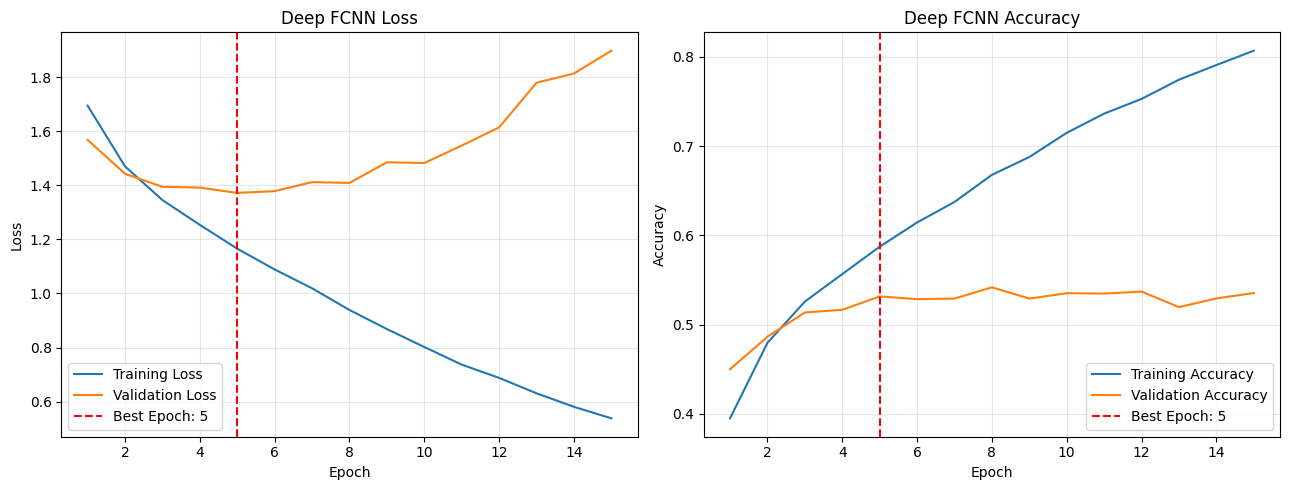

In [19]:
# Plot the deeper model loss and accuracy curves.
deep_epochs = range(1, len(deep_history["train_loss"]) + 1)

plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.plot(
    deep_epochs,
    deep_history["train_loss"],
    label="Training Loss"
)
plt.plot(
    deep_epochs,
    deep_history["validation_loss"],
    label="Validation Loss"
)
plt.axvline(
    deep_best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch: {deep_best_epoch}"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Deep FCNN Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(
    deep_epochs,
    deep_history["train_accuracy"],
    label="Training Accuracy"
)
plt.plot(
    deep_epochs,
    deep_history["validation_accuracy"],
    label="Validation Accuracy"
)
plt.axvline(
    deep_best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch: {deep_best_epoch}"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Deep FCNN Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Problem 1 Comparison


In [20]:
# Place the baseline and deeper model results in one table.
comparison_results = pd.DataFrame({
    "Model": ["Baseline FCNN", "Deep FCNN"],
    "Best Epoch": [
        baseline_best_epoch,
        deep_best_epoch
    ],
    "Training Time (seconds)": [
        baseline_training_time,
        deep_training_time
    ],
    "Training Loss": [
        baseline_train_loss,
        deep_train_loss
    ],
    "Training Accuracy": [
        baseline_train_accuracy,
        deep_train_accuracy
    ],
    "Validation Accuracy": [
        baseline_validation_accuracy,
        deep_validation_accuracy
    ],
    "Evaluation Accuracy": [
        baseline_test_accuracy,
        deep_test_accuracy
    ],
    "Trainable Parameters": [
        baseline_parameters,
        deep_parameters
    ]
})

comparison_results.round(4)

,Model,Best Epoch,Training Time (seconds),Training Loss,Training Accuracy,Validation Accuracy,Evaluation Accuracy,Trainable Parameters
0,Baseline FCNN,3,148.4910,1.2029,0.574,0.5110,0.5106,1707274
1,Deep FCNN,5,183.9485,1.0470,0.631,0.5316,0.5303,1746506


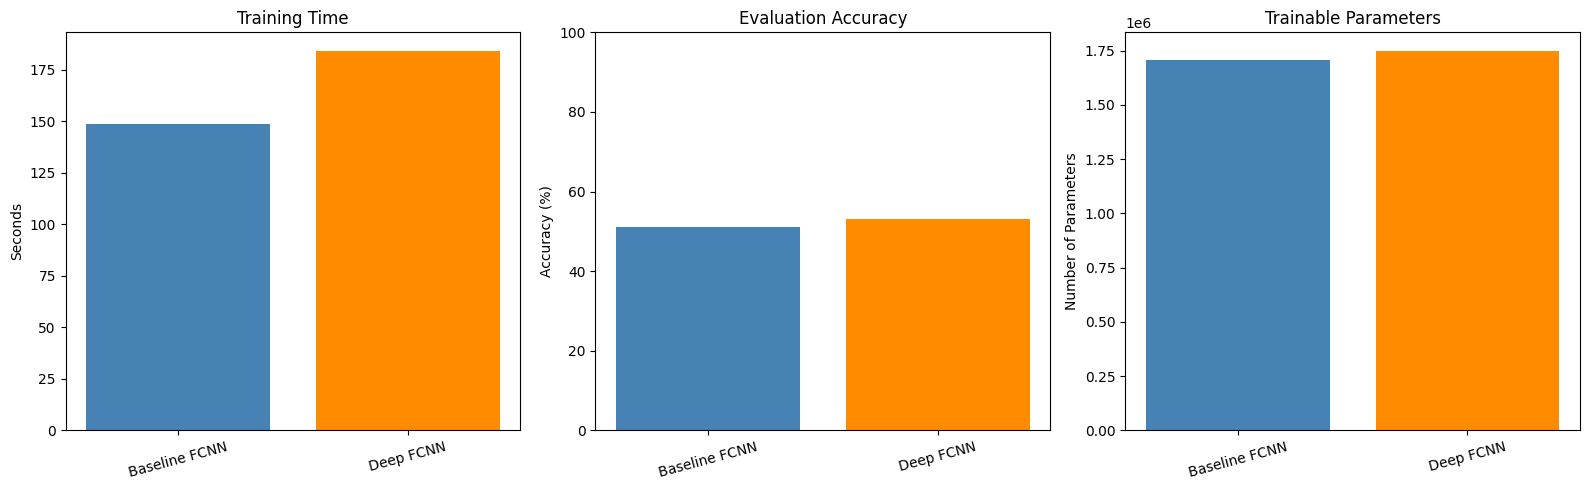

In [21]:
# Compare training time, test accuracy, and parameter count.
model_names = comparison_results["Model"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].bar(
    model_names,
    comparison_results["Training Time (seconds)"],
    color=["steelblue", "darkorange"]
)
axes[0].set_title("Training Time")
axes[0].set_ylabel("Seconds")
axes[0].tick_params(axis="x", rotation=15)

axes[1].bar(
    model_names,
    comparison_results["Evaluation Accuracy"] * 100,
    color=["steelblue", "darkorange"]
)
axes[1].set_title("Evaluation Accuracy")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis="x", rotation=15)

axes[2].bar(
    model_names,
    comparison_results["Trainable Parameters"],
    color=["steelblue", "darkorange"]
)
axes[2].set_title("Trainable Parameters")
axes[2].set_ylabel("Number of Parameters")
axes[2].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

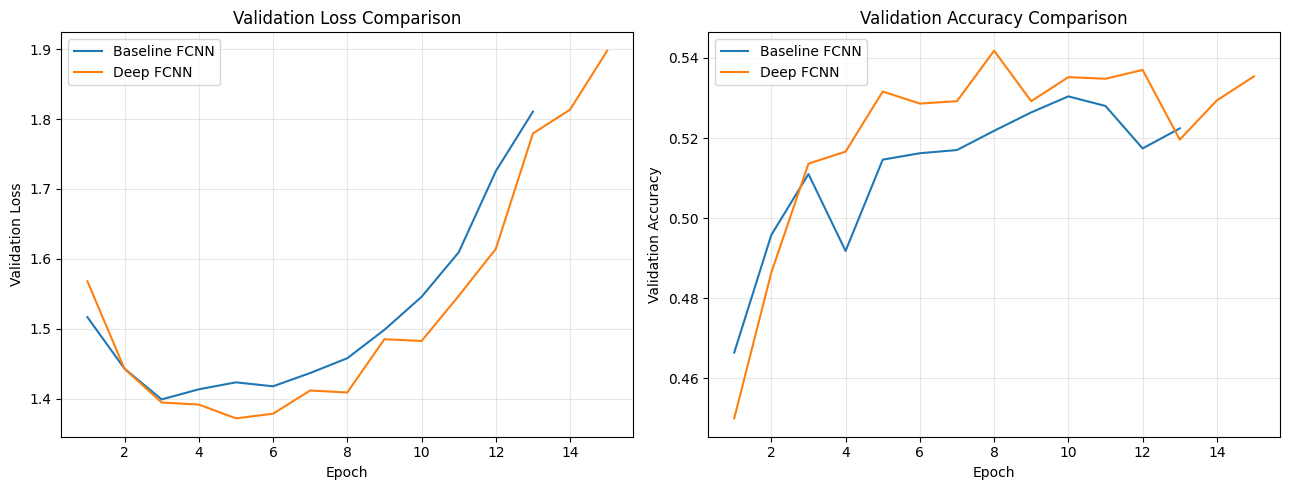

In [22]:
# Compare the validation behavior of the first two models.
baseline_epochs = range(
    1,
    len(baseline_history["validation_loss"]) + 1
)

deep_epochs = range(
    1,
    len(deep_history["validation_loss"]) + 1
)

plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.plot(
    baseline_epochs,
    baseline_history["validation_loss"],
    label="Baseline FCNN"
)
plt.plot(
    deep_epochs,
    deep_history["validation_loss"],
    label="Deep FCNN"
)
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(
    baseline_epochs,
    baseline_history["validation_accuracy"],
    label="Baseline FCNN"
)
plt.plot(
    deep_epochs,
    deep_history["validation_accuracy"],
    label="Deep FCNN"
)
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Problem 2a Ten Hidden Layer FCNN


In [23]:
# Build the FCNN with ten hidden ReLU layers.
class Deep10FCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            # Hidden layer 1
            nn.Linear(3 * 32 * 32, 512),
            nn.ReLU(),

            # Hidden layer 2
            nn.Linear(512, 256),
            nn.ReLU(),

            # Hidden layer 3
            nn.Linear(256, 128),
            nn.ReLU(),

            # Hidden layer 4
            nn.Linear(128, 64),
            nn.ReLU(),

            # Hidden layer 5
            nn.Linear(64, 64),
            nn.ReLU(),

            # Hidden layer 6
            nn.Linear(64, 64),
            nn.ReLU(),

            # Hidden layer 7
            nn.Linear(64, 64),
            nn.ReLU(),

            # Hidden layer 8
            nn.Linear(64, 64),
            nn.ReLU(),

            # Hidden layer 9
            nn.Linear(64, 64),
            nn.ReLU(),

            # Hidden layer 10
            nn.Linear(64, 64),
            nn.ReLU(),

            # Output layer
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)

In [24]:
# Create the ten-layer model and count its trainable parameters.
deep10_model = Deep10FCNN().to(device)

deep10_parameters = sum(
    parameter.numel()
    for parameter in deep10_model.parameters()
    if parameter.requires_grad
)

print(deep10_model)
print(f"Trainable parameters: {deep10_parameters:,}")

Deep10FCNN(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=128, bias=True)
    (6): ReLU()
    (7): Linear(in_features=128, out_features=64, bias=True)
    (8): ReLU()
    (9): Linear(in_features=64, out_features=64, bias=True)
    (10): ReLU()
    (11): Linear(in_features=64, out_features=64, bias=True)
    (12): ReLU()
    (13): Linear(in_features=64, out_features=64, bias=True)
    (14): ReLU()
    (15): Linear(in_features=64, out_features=64, bias=True)
    (16): ReLU()
    (17): Linear(in_features=64, out_features=64, bias=True)
    (18): ReLU()
    (19): Linear(in_features=64, out_features=64, bias=True)
    (20): ReLU()
    (21): Linear(in_features=64, out_features=10, bias=True)
  )
)
Trainable parameters: 1,771,466


In [25]:
# Train the ten-hidden-layer network with early stopping.
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

deep10_model = Deep10FCNN().to(device)

deep10_model, deep10_history, deep10_training_time, deep10_best_epoch = train_model(
    model=deep10_model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    learning_rate=0.001,
    max_epochs=100,
    patience=10
)

Epoch   1 | Train Loss: 1.9412 | Train Acc: 0.2522 | Val Loss: 1.8010 | Val Acc: 0.3016
Epoch   2 | Train Loss: 1.7216 | Train Acc: 0.3540 | Val Loss: 1.6811 | Val Acc: 0.3798
Epoch   3 | Train Loss: 1.5992 | Train Acc: 0.4171 | Val Loss: 1.5989 | Val Acc: 0.4222
Epoch   4 | Train Loss: 1.4837 | Train Acc: 0.4636 | Val Loss: 1.5068 | Val Acc: 0.4646
Epoch   5 | Train Loss: 1.3774 | Train Acc: 0.5016 | Val Loss: 1.4818 | Val Acc: 0.4670
Epoch   6 | Train Loss: 1.2931 | Train Acc: 0.5341 | Val Loss: 1.4584 | Val Acc: 0.4836
Epoch   7 | Train Loss: 1.2216 | Train Acc: 0.5637 | Val Loss: 1.4138 | Val Acc: 0.5120
Epoch   8 | Train Loss: 1.1495 | Train Acc: 0.5881 | Val Loss: 1.3967 | Val Acc: 0.5178
Epoch   9 | Train Loss: 1.0868 | Train Acc: 0.6110 | Val Loss: 1.4681 | Val Acc: 0.5082
Epoch  10 | Train Loss: 1.0303 | Train Acc: 0.6316 | Val Loss: 1.4563 | Val Acc: 0.5134
Epoch  11 | Train Loss: 0.9617 | Train Acc: 0.6572 | Val Loss: 1.4661 | Val Acc: 0.5304
Epoch  12 | Train Loss: 0.9114 |

In [26]:
# Evaluate the best ten-hidden-layer model.
criterion = nn.CrossEntropyLoss()

deep10_train_loss, deep10_train_accuracy = evaluate_model(
    deep10_model, train_loader, criterion
)

deep10_validation_loss, deep10_validation_accuracy = evaluate_model(
    deep10_model, validation_loader, criterion
)

deep10_test_loss, deep10_test_accuracy = evaluate_model(
    deep10_model, test_loader, criterion
)

deep10_parameters = sum(
    parameter.numel()
    for parameter in deep10_model.parameters()
    if parameter.requires_grad
)

print("10-Hidden-Layer FCNN Final Results")
print(f"Best epoch:           {deep10_best_epoch}")
print(f"Training time:        {deep10_training_time:.2f} seconds")
print(f"Training loss:        {deep10_train_loss:.4f}")
print(f"Training accuracy:    {deep10_train_accuracy:.4f}")
print(f"Validation loss:      {deep10_validation_loss:.4f}")
print(f"Validation accuracy:  {deep10_validation_accuracy:.4f}")
print(f"Evaluation loss:      {deep10_test_loss:.4f}")
print(f"Evaluation accuracy:  {deep10_test_accuracy:.4f}")
print(f"Trainable parameters: {deep10_parameters:,}")

10-Hidden-Layer FCNN Final Results
Best epoch:           8
Training time:        214.90 seconds
Training loss:        1.0472
Training accuracy:    0.6291
Validation loss:      1.3967
Validation accuracy:  0.5178
Evaluation loss:      1.3837
Evaluation accuracy:  0.5181
Trainable parameters: 1,771,466


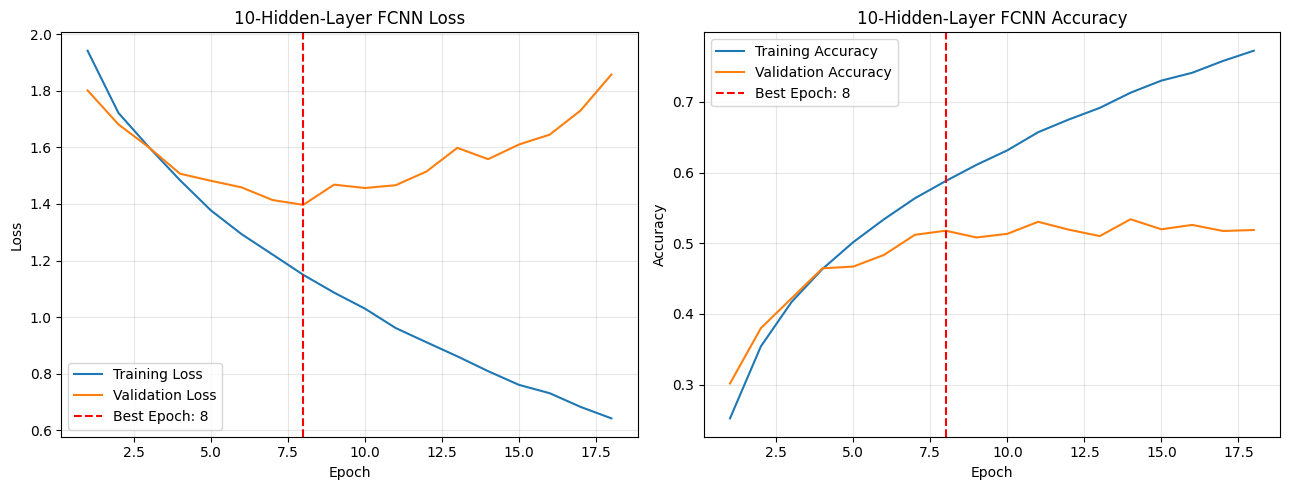

In [27]:
# Plot the ten-layer model loss and accuracy curves.
deep10_epochs = range(
    1,
    len(deep10_history["train_loss"]) + 1
)

plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.plot(
    deep10_epochs,
    deep10_history["train_loss"],
    label="Training Loss"
)
plt.plot(
    deep10_epochs,
    deep10_history["validation_loss"],
    label="Validation Loss"
)
plt.axvline(
    deep10_best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch: {deep10_best_epoch}"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("10-Hidden-Layer FCNN Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(
    deep10_epochs,
    deep10_history["train_accuracy"],
    label="Training Accuracy"
)
plt.plot(
    deep10_epochs,
    deep10_history["validation_accuracy"],
    label="Validation Accuracy"
)
plt.axvline(
    deep10_best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch: {deep10_best_epoch}"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("10-Hidden-Layer FCNN Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Depth Comparison


In [28]:
# Compare the four-layer and ten-layer model results.
depth_comparison = pd.DataFrame({
    "Model": [
        "4-Hidden-Layer FCNN",
        "10-Hidden-Layer FCNN"
    ],
    "Best Epoch": [
        deep_best_epoch,
        deep10_best_epoch
    ],
    "Training Time (seconds)": [
        deep_training_time,
        deep10_training_time
    ],
    "Training Loss": [
        deep_train_loss,
        deep10_train_loss
    ],
    "Training Accuracy": [
        deep_train_accuracy,
        deep10_train_accuracy
    ],
    "Validation Accuracy": [
        deep_validation_accuracy,
        deep10_validation_accuracy
    ],
    "Evaluation Loss": [
        deep_test_loss,
        deep10_test_loss
    ],
    "Evaluation Accuracy": [
        deep_test_accuracy,
        deep10_test_accuracy
    ],
    "Trainable Parameters": [
        deep_parameters,
        deep10_parameters
    ]
})

depth_comparison.round(4)

,Model,Best Epoch,Training Time (seconds),Training Loss,Training Accuracy,Validation Accuracy,Evaluation Loss,Evaluation Accuracy,Trainable Parameters
0,4-Hidden-Layer FCNN,5,183.9485,1.0470,0.6310,0.5316,1.3570,0.5303,1746506
1,10-Hidden-Layer FCNN,8,214.9004,1.0472,0.6291,0.5178,1.3837,0.5181,1771466


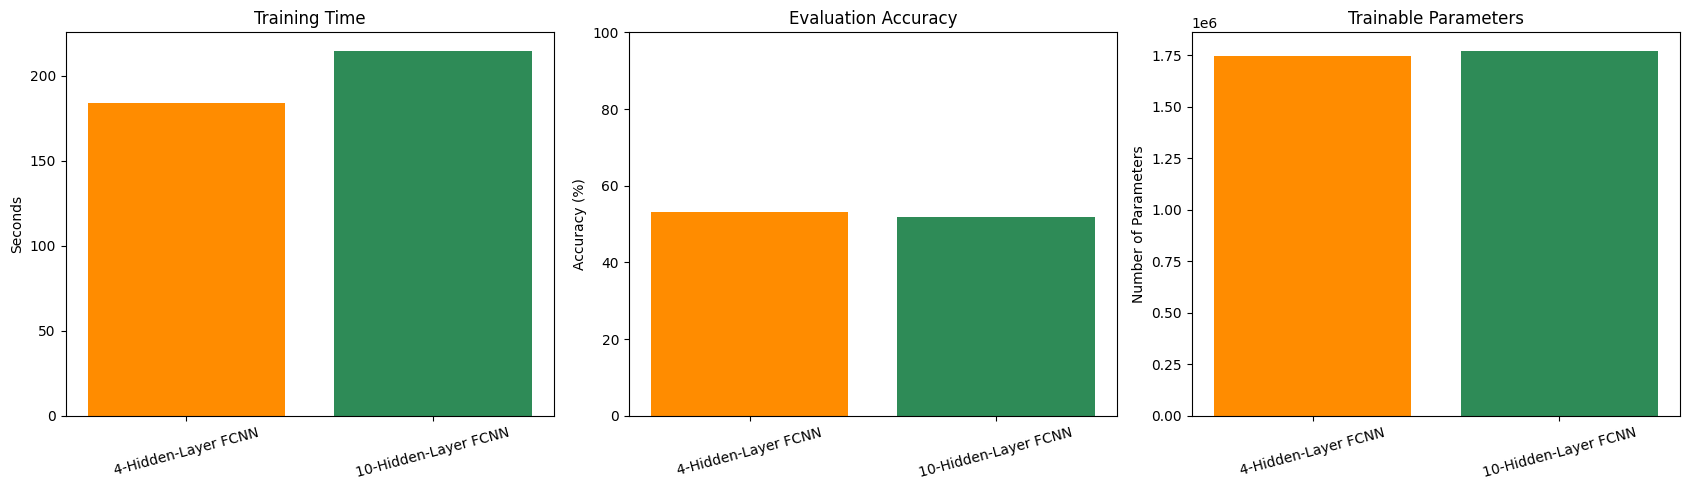

In [29]:
# Plot the main depth comparison measurements.
model_names = depth_comparison["Model"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].bar(
    model_names,
    depth_comparison["Training Time (seconds)"],
    color=["darkorange", "seagreen"]
)
axes[0].set_title("Training Time")
axes[0].set_ylabel("Seconds")
axes[0].tick_params(axis="x", rotation=15)

axes[1].bar(
    model_names,
    depth_comparison["Evaluation Accuracy"] * 100,
    color=["darkorange", "seagreen"]
)
axes[1].set_title("Evaluation Accuracy")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis="x", rotation=15)

axes[2].bar(
    model_names,
    depth_comparison["Trainable Parameters"],
    color=["darkorange", "seagreen"]
)
axes[2].set_title("Trainable Parameters")
axes[2].set_ylabel("Number of Parameters")
axes[2].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

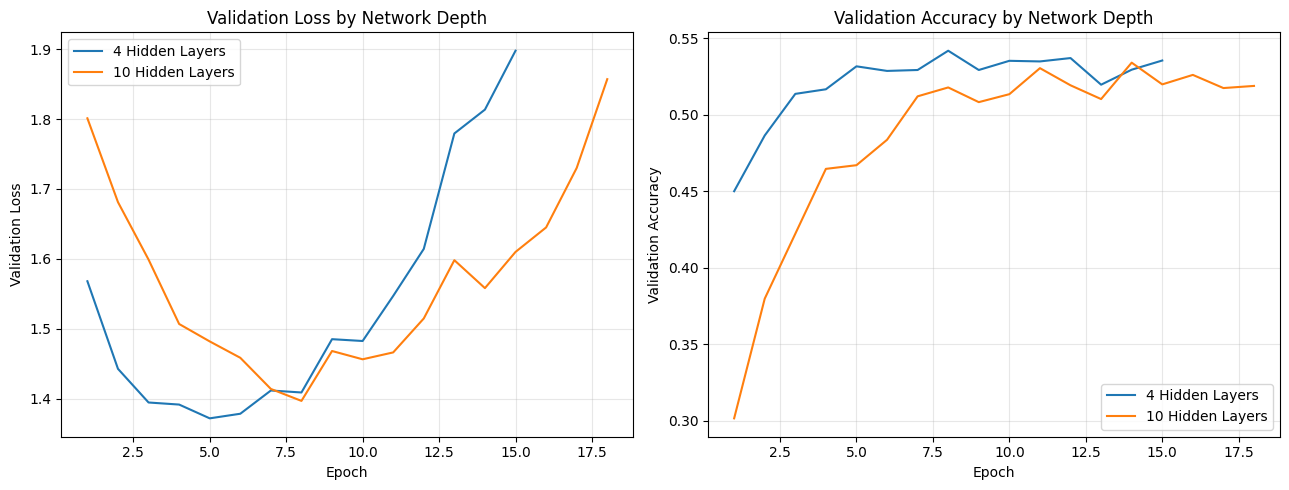

In [30]:
# Compare validation convergence for the two deeper networks.
deep4_epochs = range(
    1,
    len(deep_history["validation_loss"]) + 1
)

deep10_epochs = range(
    1,
    len(deep10_history["validation_loss"]) + 1
)

plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.plot(
    deep4_epochs,
    deep_history["validation_loss"],
    label="4 Hidden Layers"
)
plt.plot(
    deep10_epochs,
    deep10_history["validation_loss"],
    label="10 Hidden Layers"
)
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss by Network Depth")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(
    deep4_epochs,
    deep_history["validation_accuracy"],
    label="4 Hidden Layers"
)
plt.plot(
    deep10_epochs,
    deep10_history["validation_accuracy"],
    label="10 Hidden Layers"
)
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy by Network Depth")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Problem 2b Width and Activation Experiments


In [31]:
# Create a reusable two-hidden-layer FCNN with a selected activation.
class TwoHiddenFCNN(nn.Module):
    def __init__(self, hidden1, hidden2, activation):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(3 * 32 * 32, hidden1),
            activation(),

            nn.Linear(hidden1, hidden2),
            activation(),

            nn.Linear(hidden2, 10)
        )

    def forward(self, x):
        return self.network(x)

In [32]:
# Train the wider ReLU model with twice as many neurons.
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

wide_model = TwoHiddenFCNN(
    hidden1=1024,
    hidden2=512,
    activation=nn.ReLU
).to(device)

wide_parameters = sum(
    parameter.numel()
    for parameter in wide_model.parameters()
    if parameter.requires_grad
)

print(f"Wide FCNN parameters: {wide_parameters:,}")

wide_model, wide_history, wide_training_time, wide_best_epoch = train_model(
    model=wide_model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    learning_rate=0.001,
    max_epochs=100,
    patience=10
)

Wide FCNN parameters: 3,676,682
Epoch   1 | Train Loss: 1.6649 | Train Acc: 0.4100 | Val Loss: 1.5351 | Val Acc: 0.4638
Epoch   2 | Train Loss: 1.4538 | Train Acc: 0.4853 | Val Loss: 1.4690 | Val Acc: 0.4792
Epoch   3 | Train Loss: 1.3454 | Train Acc: 0.5238 | Val Loss: 1.4240 | Val Acc: 0.5000
Epoch   4 | Train Loss: 1.2575 | Train Acc: 0.5533 | Val Loss: 1.4305 | Val Acc: 0.5054
Epoch   5 | Train Loss: 1.1693 | Train Acc: 0.5856 | Val Loss: 1.4289 | Val Acc: 0.5152
Epoch   6 | Train Loss: 1.0958 | Train Acc: 0.6114 | Val Loss: 1.4451 | Val Acc: 0.5206
Epoch   7 | Train Loss: 1.0268 | Train Acc: 0.6346 | Val Loss: 1.4578 | Val Acc: 0.5316
Epoch   8 | Train Loss: 0.9466 | Train Acc: 0.6612 | Val Loss: 1.5123 | Val Acc: 0.5056
Epoch   9 | Train Loss: 0.8757 | Train Acc: 0.6866 | Val Loss: 1.5405 | Val Acc: 0.5176
Epoch  10 | Train Loss: 0.8113 | Train Acc: 0.7092 | Val Loss: 1.5970 | Val Acc: 0.5184
Epoch  11 | Train Loss: 0.7498 | Train Acc: 0.7336 | Val Loss: 1.6448 | Val Acc: 0.5306


In [33]:
# Evaluate the wider ReLU network.
wide_train_loss, wide_train_accuracy = evaluate_model(
    wide_model, train_loader, criterion
)

wide_validation_loss, wide_validation_accuracy = evaluate_model(
    wide_model, validation_loader, criterion
)

wide_test_loss, wide_test_accuracy = evaluate_model(
    wide_model, test_loader, criterion
)

print("\nWide FCNN Final Results")
print(f"Best epoch:           {wide_best_epoch}")
print(f"Training time:        {wide_training_time:.2f} seconds")
print(f"Training loss:        {wide_train_loss:.4f}")
print(f"Training accuracy:    {wide_train_accuracy:.4f}")
print(f"Validation loss:      {wide_validation_loss:.4f}")
print(f"Validation accuracy:  {wide_validation_accuracy:.4f}")
print(f"Evaluation loss:      {wide_test_loss:.4f}")
print(f"Evaluation accuracy:  {wide_test_accuracy:.4f}")
print(f"Trainable parameters: {wide_parameters:,}")


Wide FCNN Final Results
Best epoch:           3
Training time:        144.11 seconds
Training loss:        1.2190
Training accuracy:    0.5666
Validation loss:      1.4240
Validation accuracy:  0.5000
Evaluation loss:      1.4149
Evaluation accuracy:  0.4980
Trainable parameters: 3,676,682


In [34]:
# Train the baseline-width model with Sigmoid activation.
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

sigmoid_model = TwoHiddenFCNN(
    hidden1=512,
    hidden2=256,
    activation=nn.Sigmoid
).to(device)

sigmoid_parameters = sum(
    parameter.numel()
    for parameter in sigmoid_model.parameters()
    if parameter.requires_grad
)

print(f"Sigmoid FCNN parameters: {sigmoid_parameters:,}")

sigmoid_model, sigmoid_history, sigmoid_training_time, sigmoid_best_epoch = train_model(
    model=sigmoid_model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    learning_rate=0.001,
    max_epochs=100,
    patience=10
)

Sigmoid FCNN parameters: 1,707,274
Epoch   1 | Train Loss: 1.7871 | Train Acc: 0.3667 | Val Loss: 1.6678 | Val Acc: 0.4244
Epoch   2 | Train Loss: 1.6053 | Train Acc: 0.4337 | Val Loss: 1.5913 | Val Acc: 0.4406
Epoch   3 | Train Loss: 1.5161 | Train Acc: 0.4668 | Val Loss: 1.5541 | Val Acc: 0.4584
Epoch   4 | Train Loss: 1.4423 | Train Acc: 0.4921 | Val Loss: 1.5246 | Val Acc: 0.4686
Epoch   5 | Train Loss: 1.3889 | Train Acc: 0.5127 | Val Loss: 1.4994 | Val Acc: 0.4704
Epoch   6 | Train Loss: 1.3362 | Train Acc: 0.5272 | Val Loss: 1.4860 | Val Acc: 0.4844
Epoch   7 | Train Loss: 1.2851 | Train Acc: 0.5483 | Val Loss: 1.4758 | Val Acc: 0.4806
Epoch   8 | Train Loss: 1.2375 | Train Acc: 0.5643 | Val Loss: 1.4878 | Val Acc: 0.4746
Epoch   9 | Train Loss: 1.1924 | Train Acc: 0.5792 | Val Loss: 1.4804 | Val Acc: 0.4850
Epoch  10 | Train Loss: 1.1469 | Train Acc: 0.5970 | Val Loss: 1.5069 | Val Acc: 0.4844
Epoch  11 | Train Loss: 1.0963 | Train Acc: 0.6150 | Val Loss: 1.5010 | Val Acc: 0.49

In [35]:
# Evaluate the Sigmoid network.
sigmoid_train_loss, sigmoid_train_accuracy = evaluate_model(
    sigmoid_model, train_loader, criterion
)

sigmoid_validation_loss, sigmoid_validation_accuracy = evaluate_model(
    sigmoid_model, validation_loader, criterion
)

sigmoid_test_loss, sigmoid_test_accuracy = evaluate_model(
    sigmoid_model, test_loader, criterion
)

print("\nSigmoid FCNN Final Results")
print(f"Best epoch:           {sigmoid_best_epoch}")
print(f"Training time:        {sigmoid_training_time:.2f} seconds")
print(f"Training loss:        {sigmoid_train_loss:.4f}")
print(f"Training accuracy:    {sigmoid_train_accuracy:.4f}")
print(f"Validation loss:      {sigmoid_validation_loss:.4f}")
print(f"Validation accuracy:  {sigmoid_validation_accuracy:.4f}")
print(f"Evaluation loss:      {sigmoid_test_loss:.4f}")
print(f"Evaluation accuracy:  {sigmoid_test_accuracy:.4f}")
print(f"Trainable parameters: {sigmoid_parameters:,}")


Sigmoid FCNN Final Results
Best epoch:           7
Training time:        183.83 seconds
Training loss:        1.1993
Training accuracy:    0.5849
Validation loss:      1.4758
Validation accuracy:  0.4806
Evaluation loss:      1.4563
Evaluation accuracy:  0.4944
Trainable parameters: 1,707,274


In [36]:
# Train the baseline-width model with Tanh activation.
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

tanh_model = TwoHiddenFCNN(
    hidden1=512,
    hidden2=256,
    activation=nn.Tanh
).to(device)

tanh_parameters = sum(
    parameter.numel()
    for parameter in tanh_model.parameters()
    if parameter.requires_grad
)

print(f"Tanh FCNN parameters: {tanh_parameters:,}")

tanh_model, tanh_history, tanh_training_time, tanh_best_epoch = train_model(
    model=tanh_model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    learning_rate=0.001,
    max_epochs=100,
    patience=10
)

Tanh FCNN parameters: 1,707,274
Epoch   1 | Train Loss: 1.7969 | Train Acc: 0.3733 | Val Loss: 1.7255 | Val Acc: 0.3978
Epoch   2 | Train Loss: 1.6609 | Train Acc: 0.4240 | Val Loss: 1.6793 | Val Acc: 0.4170
Epoch   3 | Train Loss: 1.5991 | Train Acc: 0.4474 | Val Loss: 1.6373 | Val Acc: 0.4416
Epoch   4 | Train Loss: 1.5442 | Train Acc: 0.4638 | Val Loss: 1.6083 | Val Acc: 0.4492
Epoch   5 | Train Loss: 1.4989 | Train Acc: 0.4818 | Val Loss: 1.6016 | Val Acc: 0.4468
Epoch   6 | Train Loss: 1.4595 | Train Acc: 0.4939 | Val Loss: 1.5835 | Val Acc: 0.4514
Epoch   7 | Train Loss: 1.4179 | Train Acc: 0.5081 | Val Loss: 1.5734 | Val Acc: 0.4494
Epoch   8 | Train Loss: 1.3864 | Train Acc: 0.5195 | Val Loss: 1.5766 | Val Acc: 0.4582
Epoch   9 | Train Loss: 1.3467 | Train Acc: 0.5303 | Val Loss: 1.5741 | Val Acc: 0.4596
Epoch  10 | Train Loss: 1.3263 | Train Acc: 0.5398 | Val Loss: 1.5937 | Val Acc: 0.4664
Epoch  11 | Train Loss: 1.2893 | Train Acc: 0.5525 | Val Loss: 1.5739 | Val Acc: 0.4592


In [37]:
# Evaluate the Tanh network.
tanh_train_loss, tanh_train_accuracy = evaluate_model(
    tanh_model, train_loader, criterion
)

tanh_validation_loss, tanh_validation_accuracy = evaluate_model(
    tanh_model, validation_loader, criterion
)

tanh_test_loss, tanh_test_accuracy = evaluate_model(
    tanh_model, test_loader, criterion
)

print("\nTanh FCNN Final Results")
print(f"Best epoch:           {tanh_best_epoch}")
print(f"Training time:        {tanh_training_time:.2f} seconds")
print(f"Training loss:        {tanh_train_loss:.4f}")
print(f"Training accuracy:    {tanh_train_accuracy:.4f}")
print(f"Validation loss:      {tanh_validation_loss:.4f}")
print(f"Validation accuracy:  {tanh_validation_accuracy:.4f}")
print(f"Evaluation loss:      {tanh_test_loss:.4f}")
print(f"Evaluation accuracy:  {tanh_test_accuracy:.4f}")
print(f"Trainable parameters: {tanh_parameters:,}")


Tanh FCNN Final Results
Best epoch:           12
Training time:        244.64 seconds
Training loss:        1.1669
Training accuracy:    0.6007
Validation loss:      1.5704
Validation accuracy:  0.4692
Evaluation loss:      1.5633
Evaluation accuracy:  0.4703
Trainable parameters: 1,707,274


In [38]:
# Print the final wide ReLU results again for comparison.
wide_train_loss, wide_train_accuracy = evaluate_model(
    wide_model, train_loader, criterion
)

wide_validation_loss, wide_validation_accuracy = evaluate_model(
    wide_model, validation_loader, criterion
)

wide_test_loss, wide_test_accuracy = evaluate_model(
    wide_model, test_loader, criterion
)

wide_parameters = sum(
    parameter.numel()
    for parameter in wide_model.parameters()
    if parameter.requires_grad
)

print("Wide FCNN Final Results")
print(f"Best epoch:           {wide_best_epoch}")
print(f"Training time:        {wide_training_time:.2f} seconds")
print(f"Training loss:        {wide_train_loss:.4f}")
print(f"Training accuracy:    {wide_train_accuracy:.4f}")
print(f"Validation loss:      {wide_validation_loss:.4f}")
print(f"Validation accuracy:  {wide_validation_accuracy:.4f}")
print(f"Evaluation loss:      {wide_test_loss:.4f}")
print(f"Evaluation accuracy:  {wide_test_accuracy:.4f}")
print(f"Trainable parameters: {wide_parameters:,}")

Wide FCNN Final Results
Best epoch:           3
Training time:        144.11 seconds
Training loss:        1.2190
Training accuracy:    0.5666
Validation loss:      1.4240
Validation accuracy:  0.5000
Evaluation loss:      1.4149
Evaluation accuracy:  0.4980
Trainable parameters: 3,676,682


## Architecture Comparison


In [39]:
# Create one table for the width and activation experiments.
architecture_comparison = pd.DataFrame({
    "Model": [
        "Baseline ReLU",
        "Wide ReLU",
        "Sigmoid",
        "Tanh"
    ],
    "Best Epoch": [
        baseline_best_epoch,
        wide_best_epoch,
        sigmoid_best_epoch,
        tanh_best_epoch
    ],
    "Training Time (seconds)": [
        baseline_training_time,
        wide_training_time,
        sigmoid_training_time,
        tanh_training_time
    ],
    "Training Loss": [
        baseline_train_loss,
        wide_train_loss,
        sigmoid_train_loss,
        tanh_train_loss
    ],
    "Training Accuracy": [
        baseline_train_accuracy,
        wide_train_accuracy,
        sigmoid_train_accuracy,
        tanh_train_accuracy
    ],
    "Validation Accuracy": [
        baseline_validation_accuracy,
        wide_validation_accuracy,
        sigmoid_validation_accuracy,
        tanh_validation_accuracy
    ],
    "Evaluation Accuracy": [
        baseline_test_accuracy,
        wide_test_accuracy,
        sigmoid_test_accuracy,
        tanh_test_accuracy
    ],
    "Trainable Parameters": [
        baseline_parameters,
        wide_parameters,
        sigmoid_parameters,
        tanh_parameters
    ]
})

architecture_comparison.round(4)

,Model,Best Epoch,Training Time (seconds),Training Loss,Training Accuracy,Validation Accuracy,Evaluation Accuracy,Trainable Parameters
0,Baseline ReLU,3,148.4910,1.2029,0.5740,0.5110,0.5106,1707274
1,Wide ReLU,3,144.1119,1.2190,0.5666,0.5000,0.4980,3676682
2,Sigmoid,7,183.8256,1.1993,0.5849,0.4806,0.4944,1707274
3,Tanh,12,244.6404,1.1669,0.6007,0.4692,0.4703,1707274


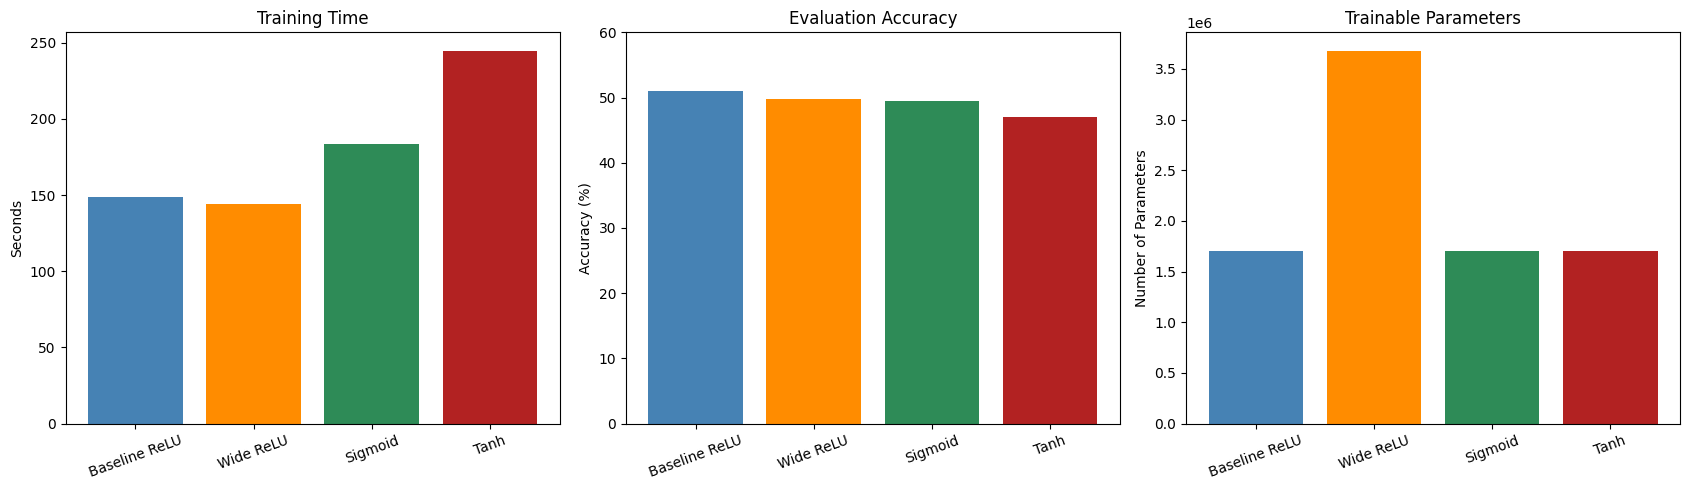

In [40]:
# Plot time, test accuracy, and parameters for the four experiments.
model_names = architecture_comparison["Model"]
colors = ["steelblue", "darkorange", "seagreen", "firebrick"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].bar(
    model_names,
    architecture_comparison["Training Time (seconds)"],
    color=colors
)
axes[0].set_title("Training Time")
axes[0].set_ylabel("Seconds")
axes[0].tick_params(axis="x", rotation=20)

axes[1].bar(
    model_names,
    architecture_comparison["Evaluation Accuracy"] * 100,
    color=colors
)
axes[1].set_title("Evaluation Accuracy")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_ylim(0, 60)
axes[1].tick_params(axis="x", rotation=20)

axes[2].bar(
    model_names,
    architecture_comparison["Trainable Parameters"],
    color=colors
)
axes[2].set_title("Trainable Parameters")
axes[2].set_ylabel("Number of Parameters")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

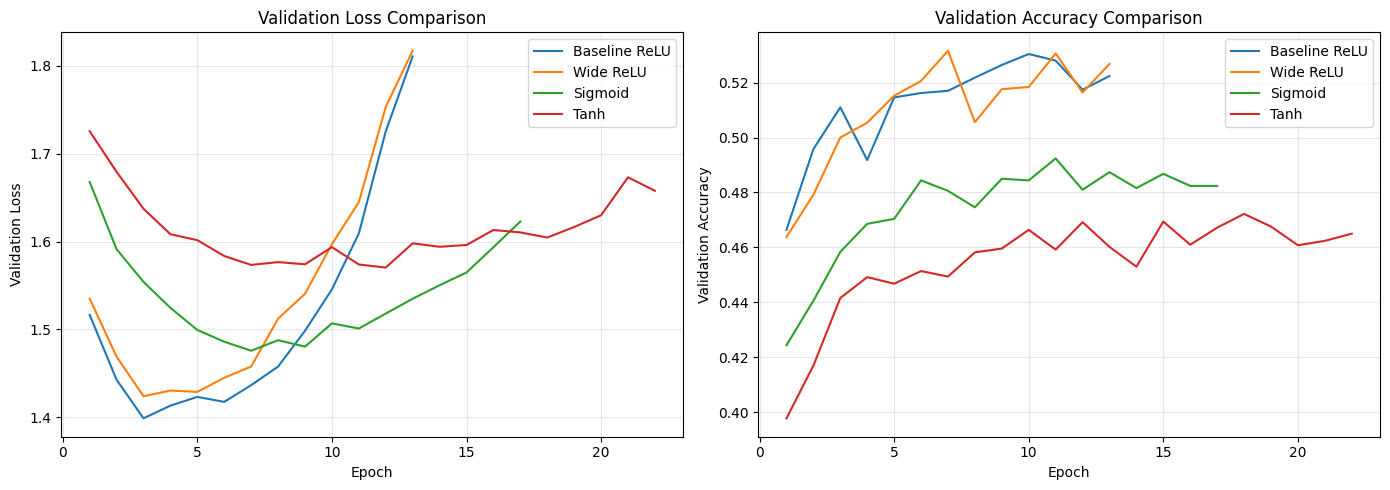

In [41]:
# Compare validation convergence for ReLU, Sigmoid, and Tanh.
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(
    range(1, len(baseline_history["validation_loss"]) + 1),
    baseline_history["validation_loss"],
    label="Baseline ReLU"
)

plt.plot(
    range(1, len(wide_history["validation_loss"]) + 1),
    wide_history["validation_loss"],
    label="Wide ReLU"
)

plt.plot(
    range(1, len(sigmoid_history["validation_loss"]) + 1),
    sigmoid_history["validation_loss"],
    label="Sigmoid"
)

plt.plot(
    range(1, len(tanh_history["validation_loss"]) + 1),
    tanh_history["validation_loss"],
    label="Tanh"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)

plt.plot(
    range(1, len(baseline_history["validation_accuracy"]) + 1),
    baseline_history["validation_accuracy"],
    label="Baseline ReLU"
)

plt.plot(
    range(1, len(wide_history["validation_accuracy"]) + 1),
    wide_history["validation_accuracy"],
    label="Wide ReLU"
)

plt.plot(
    range(1, len(sigmoid_history["validation_accuracy"]) + 1),
    sigmoid_history["validation_accuracy"],
    label="Sigmoid"
)

plt.plot(
    range(1, len(tanh_history["validation_accuracy"]) + 1),
    tanh_history["validation_accuracy"],
    label="Tanh"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Overall Model Comparison


In [42]:
# Combine the final results from all six networks.
all_models_comparison = pd.DataFrame({
    "Model": [
        "Baseline ReLU",
        "4-Hidden-Layer ReLU",
        "10-Hidden-Layer ReLU",
        "Wide ReLU",
        "Sigmoid",
        "Tanh"
    ],
    "Training Time": [
        baseline_training_time,
        deep_training_time,
        deep10_training_time,
        wide_training_time,
        sigmoid_training_time,
        tanh_training_time
    ],
    "Training Accuracy": [
        baseline_train_accuracy,
        deep_train_accuracy,
        deep10_train_accuracy,
        wide_train_accuracy,
        sigmoid_train_accuracy,
        tanh_train_accuracy
    ],
    "Evaluation Accuracy": [
        baseline_test_accuracy,
        deep_test_accuracy,
        deep10_test_accuracy,
        wide_test_accuracy,
        sigmoid_test_accuracy,
        tanh_test_accuracy
    ],
    "Parameters": [
        baseline_parameters,
        deep_parameters,
        deep10_parameters,
        wide_parameters,
        sigmoid_parameters,
        tanh_parameters
    ]
})

all_models_comparison.round(4)

,Model,Training Time,Training Accuracy,Evaluation Accuracy,Parameters
0,Baseline ReLU,148.4910,0.5740,0.5106,1707274
1,4-Hidden-Layer ReLU,183.9485,0.6310,0.5303,1746506
2,10-Hidden-Layer ReLU,214.9004,0.6291,0.5181,1771466
3,Wide ReLU,144.1119,0.5666,0.4980,3676682
4,Sigmoid,183.8256,0.5849,0.4944,1707274
5,Tanh,244.6404,0.6007,0.4703,1707274


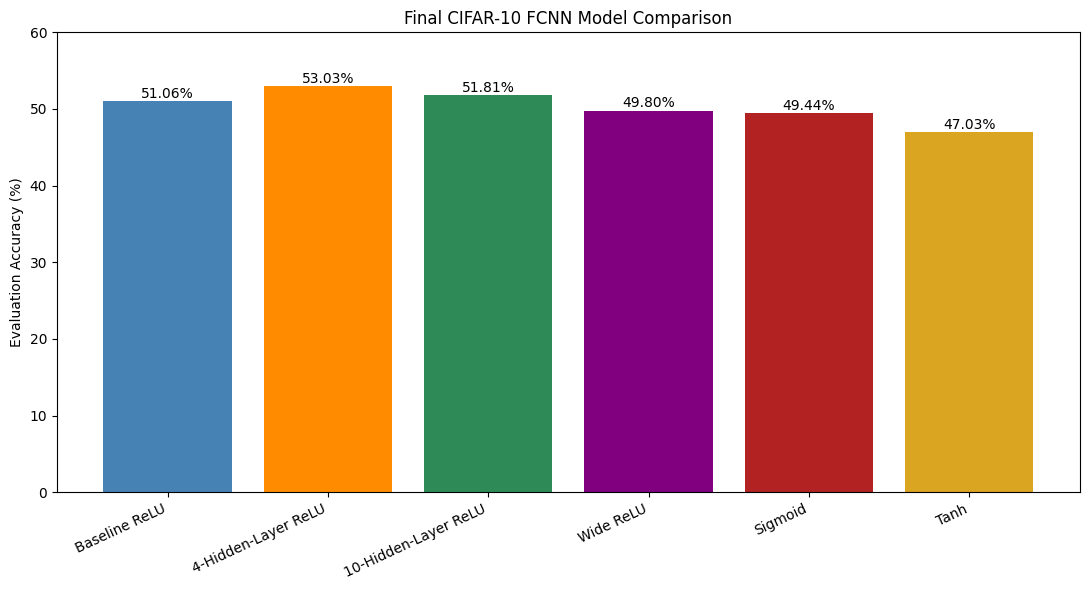

In [43]:
# Plot the final evaluation accuracy ranking.
plt.figure(figsize=(11, 6))

bars = plt.bar(
    all_models_comparison["Model"],
    all_models_comparison["Evaluation Accuracy"] * 100,
    color=[
        "steelblue",
        "darkorange",
        "seagreen",
        "purple",
        "firebrick",
        "goldenrod"
    ]
)

plt.ylabel("Evaluation Accuracy (%)")
plt.title("Final CIFAR-10 FCNN Model Comparison")
plt.ylim(0, 60)
plt.xticks(rotation=25, ha="right")

for bar in bars:
    value = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.4,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()